# Step 7: Single-airport removal and H3 evaluation

**Scope.** This notebook removes each observed airport individually, calculates the approved loss measures, and applies the approved H3 evaluation. Randomized networks are not used.

**Primary outcome.** ΔE_i = Efficiency(G, none removed) − Efficiency(G, {i} removed), with the original N(N−1) denominator.

**Supplementary outcome.** For the surviving airports S (all airports except i), D_i is the mean of 1/d across ordered pairs in S before removal minus the same mean after removal, each with denominator (N−1)(N−2).

**Identity used as a calculation check.** ΔE_i = direct_i / (N(N−1)) + ((N−2)/N) × D_i, where direct_i sums 1/d over all ordered pairs involving i.

**Interpretation.** These results show association or predictive improvement in observed structure. They are not causal claims. The 0.02 R² threshold is a project-specific practical-effect threshold, not a universal statistical standard.

## Section 7.0: Setup and accepted inputs

**Environment.** Run this notebook in the project environment: Python 3.13.5 with the packages in `requirements.txt`, installed once with `python -m pip install -r requirements.txt`. Do not install packages from inside the notebook. Unpinned installs change library versions for every notebook, and the Louvain results of NB03 and NB04 depend on the NetworkX version. See `RUN_ORDER.md` for the order in which the notebooks must be run.

In [ ]:
# Environment check: installs nothing; warns if the running versions differ from requirements.txt.
import os as _os
import platform as _platform
import re as _re
import warnings as _warnings
from importlib.metadata import PackageNotFoundError as _PkgNotFound, version as _pkg_version
from pathlib import Path as _Path

_root = _os.environ.get("NETWORK_ANALYSIS_LOCAL_ROOT")
_req = (_Path(_root).expanduser().resolve() if _root else _Path.cwd()) / "requirements.txt"
if _req.is_file():
    _text = _req.read_text(encoding="utf-8")
    _mismatch = []
    _py = _re.search(r"Python (\d+\.\d+\.\d+)", _text)
    print(f"{'Python':13s} {_platform.python_version():14s} pinned {_py.group(1) if _py else '?'}")
    if _py and _platform.python_version() != _py.group(1):
        _mismatch.append("Python")
    for _line in _text.splitlines():
        _line = _line.split("#")[0].strip()
        if "==" not in _line:
            continue
        _name, _pinned = (_s.strip() for _s in _line.split("==", 1))
        try:
            _installed = _pkg_version(_name)
        except _PkgNotFound:
            _installed = "not installed"
        print(f"{_name:13s} {_installed:14s} pinned {_pinned}")
        if _installed != _pinned:
            _mismatch.append(_name)
    if _mismatch:
        _warnings.warn("Versions differ from requirements.txt for: " + ", ".join(_mismatch)
                       + ". Results may differ from the reported values; see RUN_ORDER.md.")
    else:
        print("All versions match requirements.txt.")
else:
    _warnings.warn(f"requirements.txt not found at {_req}; versions were not checked.")

In [2]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path

# Use an explicit local project directory, the current project directory,
# or the configured Google Drive directory when running in Colab.
LOCAL_PROJECT_ROOT = os.environ.get("NETWORK_ANALYSIS_LOCAL_ROOT")

if LOCAL_PROJECT_ROOT:
    BASE = Path(LOCAL_PROJECT_ROOT).expanduser().resolve() / "Data"
elif (Path.cwd() / "Data").is_dir():
    BASE = Path.cwd() / "Data"
else:
    from google.colab import drive
    drive.mount("/content/drive")

    # Notice the trailing space after 'Network Analysis '
    BASE = Path("/content/drive/MyDrive/Network Analysis /Data")

PROCESSED = BASE / "Processed"
H3_STORE = PROCESSED / "H3"
PROJECT_ROOT = BASE.parent
TABLES = PROJECT_ROOT / "Results" / "Tables"
FIGURES = PROJECT_ROOT / "Results" / "Figures"
H3_STORE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

AIRLINES = ["AA", "DL", "WN"]
AIRLINE_INDEX = {a: i for i, a in enumerate(AIRLINES)}
MASTER_SEED = 20250401
STAGE_H3_BOOTSTRAP = 8
BOOTSTRAPS = 2000
GAIN_THRESHOLD = 0.02
TOP_K = [10, 20]
EXPECTED_ELIGIBLE = {"AA": 175, "DL": 142, "WN": 102}
MIN_BIN_AIRPORTS = 5
LOUVAIN_RUNS = 100
RANK_DECIMALS = 12


def ranking_values(values):
    """Fixed, data-independent quantization for numerical ties; raw measures retained."""
    return np.round(np.asarray(values, dtype=float), RANK_DECIMALS)


def numerical_top(frame, column, k):
    """Use the same numerical-tie rule for every reported top-k list."""
    ids = frame["AirportID"].to_numpy()
    return frame.iloc[np.lexsort((ids, -ranking_values(frame[column])))[:k]]


validation = []
timings = {}


class StopProtocolError(RuntimeError):
    pass


def check(name, condition, detail=""):
    passed = bool(condition)
    validation.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": str(detail)})
    if not passed:
        pd.DataFrame(validation).to_csv(TABLES / "07_validation_checks.csv", index=False)
        raise StopProtocolError(f"FAILED: {name}. {detail}")


master = pd.read_csv(TABLES / "03_airport_master.csv", dtype={"Degree bin": str})
weighted_participation = pd.read_csv(TABLES / "03_bridging_weighted_participation.csv")
run_labels = pd.read_csv(TABLES / "03_louvain_run_labels_binary.csv")
step6_intact = pd.read_csv(TABLES / "06_intact_baselines.csv")
OBS = {}

for airline in AIRLINES:
    nodes = pd.read_csv(PROCESSED / f"{airline}_nodes.csv")
    edges = pd.read_csv(PROCESSED / f"{airline}_edges.csv")
    ids = np.sort(nodes["airport_id"].to_numpy(dtype=np.int64))
    info = master[master["Airline"] == airline].sort_values("AirportID").reset_index(drop=True)
    assert np.array_equal(info["AirportID"].to_numpy(), ids)
    OBS[airline] = {
        "ids": ids, "n": len(ids), "info": info,
        "source": np.searchsorted(ids, edges["source"].to_numpy(dtype=np.int64)),
        "target": np.searchsorted(ids, edges["target"].to_numpy(dtype=np.int64))
    }

print("Accepted inputs loaded for", ", ".join(AIRLINES))

Accepted inputs loaded for AA, DL, WN


## Section 7.1: Single-airport removal

Each airport is removed once, and the remaining network is evaluated using the original airport set as its universe.

In [3]:
def inverse_distance_matrix(source, target, n, removed=None):
    A = csr_matrix((np.ones(len(source), dtype=float), (source, target)), shape=(n, n))
    if removed is not None:
        keep = np.ones(n, dtype=bool)
        keep[removed] = False
        A = A[keep, :][:, keep]
    d = shortest_path(A, method="D", unweighted=True, directed=True)
    inverse = np.zeros_like(d)
    reachable = np.isfinite(d) & (d > 0)
    inverse[reachable] = 1.0 / d[reachable]
    return inverse


single_rows = []
started = time.perf_counter()

for airline in AIRLINES:
    obs = OBS[airline]
    n, source, target = obs["n"], obs["source"], obs["target"]
    before = inverse_distance_matrix(source, target, n)
    denominator = n * (n - 1)
    survivor_denominator = (n - 1) * (n - 2)
    intact_efficiency = before.sum() / denominator
    info = obs["info"]

    for i in range(n):
        after = inverse_distance_matrix(source, target, n, removed=i)
        efficiency_after = after.sum() / denominator
        keep = np.ones(n, dtype=bool)
        keep[i] = False
        survivors_before = before[keep, :][:, keep].sum() / survivor_denominator
        survivors_after = after.sum() / survivor_denominator
        direct = before[i, :].sum() + before[:, i].sum()
        loss = intact_efficiency - efficiency_after
        damage = survivors_before - survivors_after
        row = info.iloc[i]
        single_rows.append({
            "Airline": airline, "AirportID": int(obs["ids"][i]), "Code": row["Code"], "Degree": int(row["Degree"]),
            "Eligible (degree >= 2)": bool(row["Eligible (degree >= 2)"]),
            "Betweenness": row["Betweenness"], "Core number": int(row["Core number"]),
            "Participation mean": row["Participation mean"], "Total strength (supplementary)": row["Total strength"],
            "Degree bin": row["Degree bin"], "Bin airports": row["Bin airports"], "Bin assessable": row["Bin assessable"],
            "Intact efficiency": intact_efficiency, "Efficiency after removal": efficiency_after,
            "Efficiency loss": loss, "Relative efficiency loss": loss / intact_efficiency,
            "Direct contribution": direct,
            "Survivor efficiency before": survivors_before, "Survivor efficiency after": survivors_after,
            "Surviving-airport damage": damage, "Relative surviving-airport damage": damage / survivors_before
        })

single_df = pd.DataFrame(single_rows)
single_df["Efficiency loss ranking input"] = ranking_values(single_df["Efficiency loss"])
single_df["Participation ranking input"] = ranking_values(single_df["Participation mean"])

single_df.to_csv(TABLES / "07_single_airport_outcomes.csv", index=False)
timings["Single-airport removal"] = time.perf_counter() - started

eligible_df = single_df[single_df["Eligible (degree >= 2)"]].copy()
display(single_df.groupby("Airline").agg(Airports=("AirportID", "count"), Eligible=("Eligible (degree >= 2)", "sum"),
                                         Maximum_loss=("Efficiency loss", "max"), Median_loss=("Efficiency loss", "median")).round(5))

,Airports,Eligible,Maximum_loss,Median_loss
Airline,,,,
AA,230,175,0.12851,0.00427
DL,212,142,0.14088,0.00446
WN,104,102,0.02376,0.01037


## Section 7.2: Validation of the single-airport results

Validation runs before any H3 evaluation. A failure stops the notebook.

In [4]:
for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]
    data = single_df[single_df["Airline"] == airline]
    check(f"{airline}: one row per airport", len(data) == n and data["AirportID"].is_unique, len(data))

    intact = step6_intact[(step6_intact["Airline"] == airline) & (step6_intact["Network set"] == "observed")]["Intact efficiency"].iloc[0]
    check(f"{airline}: intact efficiency matches Step 6", np.isclose(data["Intact efficiency"].iloc[0], intact, rtol=0, atol=1e-12))

    identity = data["Direct contribution"] / (n * (n - 1)) + ((n - 2) / n) * data["Surviving-airport damage"]
    check(f"{airline}: decomposition identity holds for every airport", np.allclose(data["Efficiency loss"], identity, rtol=0, atol=1e-12), n)
    check(f"{airline}: surviving-airport damage is non-negative", (data["Surviving-airport damage"] >= -1e-12).all())
    zero_b = data[data["Betweenness"] == 0]
    check(f"{airline}: zero-betweenness airports have zero surviving-airport damage", (zero_b["Surviving-airport damage"].abs() <= 1e-12).all(), len(zero_b))
    check(f"{airline}: eligible airport count", int(data["Eligible (degree >= 2)"].sum()) == EXPECTED_ELIGIBLE[airline], int(data["Eligible (degree >= 2)"].sum()))

    G = nx.DiGraph()
    G.add_nodes_from(range(n))
    G.add_edges_from(zip(obs["source"].tolist(), obs["target"].tolist()))
    check(f"{airline}: degree matches the network", all(G.out_degree(i) == G.in_degree(i) == data["Degree"].iloc[i] for i in range(n)))
    sample = np.linspace(0, n - 1, 8, dtype=int).tolist() + np.lexsort((data["AirportID"].to_numpy(), -data["Degree"].to_numpy()))[:3].tolist()

    for i in sample:
        H = G.copy()
        H.remove_node(i)
        lengths = [d for u, targets in nx.all_pairs_shortest_path_length(H) for v, d in targets.items() if u != v]
        efficiency_nx = sum(1 / d for d in lengths) / (n * (n - 1))
        check(f"{airline} airport index {i}: efficiency after removal matches NetworkX", np.isclose(efficiency_nx, data["Efficiency after removal"].iloc[i], rtol=0, atol=1e-12))

check("All airports retained in descriptive output", len(single_df) == sum(OBS[a]["n"] for a in AIRLINES), len(single_df))

## Section 7.3: Associations and top-k comparisons

Spearman correlations and top-k overlaps are descriptive. "Eligible" is the degree ≥ 2 population used for H3; "All airports" retains every airport. Strength is supplementary. All floating-point ranking inputs are rounded to 12 decimals; raw measurements remain in the exports. Rankings use descending quantized values with ties by ascending BTS ID.

In [5]:
MEASURE_COLUMNS = {"Degree": "Degree", "Betweenness": "Betweenness", "Core number": "Core number",
                   "Mean participation": "Participation mean", "Total strength (supplementary)": "Total strength (supplementary)"}
spearman_rows, topk_rows = [], []

for airline in AIRLINES:
    for population, frame in [("Eligible (degree >= 2)", eligible_df), ("All airports", single_df)]:
        data = frame[frame["Airline"] == airline].reset_index(drop=True)
        ids = data["AirportID"].to_numpy()
        loss_order = np.lexsort((ids, -ranking_values(data["Efficiency loss"])))

        for label, column in MEASURE_COLUMNS.items():
            spearman_rows.append({"Airline": airline, "Population": population, "Measure": label, "Airports": len(data),
                                  "Spearman with efficiency loss": pd.Series(ranking_values(data[column])).corr(pd.Series(ranking_values(data["Efficiency loss"])), method="spearman")})
            measure_order = np.lexsort((ids, -ranking_values(data[column])))
            for k in TOP_K:
                overlap = len(set(loss_order[:k].tolist()) & set(measure_order[:k].tolist()))
                topk_rows.append({"Airline": airline, "Population": population, "Measure": label, "k": k,
                                  "Airports in both top k": overlap, "Overlap share": overlap / k})

spearman_df = pd.DataFrame(spearman_rows)
topk_df = pd.DataFrame(topk_rows)
spearman_df.to_csv(TABLES / "07_spearman_correlations.csv", index=False)
topk_df.to_csv(TABLES / "07_topk_overlap.csv", index=False)
display(spearman_df.pivot_table(index=["Population", "Measure"], columns="Airline", values="Spearman with efficiency loss").round(3))
display(topk_df.pivot_table(index=["Population", "Measure", "k"], columns="Airline", values="Airports in both top k"))

top_rows = []
for airline in AIRLINES:
    data = single_df[single_df["Airline"] == airline]
    for rank, (_, row) in enumerate(numerical_top(data, "Efficiency loss", 10).iterrows(), 1):
        top_rows.append({"Airline": airline, "Rank": rank, "Code": row["Code"], "Degree": row["Degree"], "Efficiency loss": row["Efficiency loss"],
                         "Relative efficiency loss": row["Relative efficiency loss"], "Surviving-airport damage": row["Surviving-airport damage"],
                         "Betweenness": row["Betweenness"], "Core number": row["Core number"], "Mean participation": row["Participation mean"]})
top_losses_df = pd.DataFrame(top_rows)
top_losses_df.to_csv(TABLES / "07_top_efficiency_loss_airports.csv", index=False)
display(top_losses_df.round(4))

Airline                                                   AA     DL     WN
Population             Measure                                            
All airports           Betweenness                     0.639  0.622  0.855
                       Core number                     0.924  0.914  0.951
                       Degree                          0.924  0.914  0.973
                       Mean participation              0.856  0.910  0.665
                       Total strength (supplementary)  0.835  0.883  0.924
Eligible (degree >= 2) Betweenness                     0.709  0.651  0.852
                       Core number                     0.909  0.954  0.948
                       Degree                          0.909  0.955  0.972
                       Mean participation              0.800  0.893  0.646
                       Total strength (supplementary)  0.842  0.866  0.922

Airline                                                     AA    DL    WN
Population             Measure                        k                   
All airports           Betweenness                    10  10.0  10.0   9.0
                                                      20  19.0  18.0  19.0
                       Core number                    10   6.0   7.0   4.0
                                                      20  20.0  20.0  14.0
                       Degree                         10   9.0  10.0   9.0
                                                      20  20.0  20.0  19.0
                       Mean participation             10   2.0   0.0   5.0
                                                      20   7.0  13.0  10.0
                       Total strength (supplementary) 10   9.0   9.0   9.0
                                                      20  16.0  18.0  18.0
Eligible (degree >= 2) Betweenness                    10  10.0  10.0   9.0
                                                      20  19.0  18.0  19.0
                       Core number                    10   6.0   7.0   4.0
                                                      20  20.0  20.0  14.0
                       Degree                         10   9.0  10.0   9.0
                                                      20  20.0  20.0  19.0
                       Mean participation             10   2.0   0.0   5.0
                                                      20   7.0  13.0  10.0
                       Total strength (supplementary) 10   9.0   9.0   9.0
                                                      20  16.0  18.0  18.0

,Airline,Rank,Code,Degree,Efficiency loss,Relative efficiency loss,Surviving-airport damage,Betweenness,Core number,Mean participation
0,AA,1,DFW,182,0.1285,0.2610,0.1218,0.4631,11,0.6793
1,AA,2,CLT,136,0.0529,0.1073,0.0463,0.2136,11,0.6081
2,AA,3,ORD,136,0.0386,0.0784,0.0320,0.1849,11,0.7124
3,AA,4,PHX,92,0.0170,0.0345,0.0110,0.1022,11,0.5885
4,AA,5,PHL,88,0.0129,0.0261,0.0069,0.0514,11,0.6031
5,AA,6,JFK,24,0.0078,0.0159,0.0031,0.0096,11,0.6473
6,AA,7,DCA,86,0.0061,0.0124,0.0001,0.0419,11,0.5662
7,AA,8,MIA,75,0.0058,0.0117,0.0000,0.0220,11,0.7200
8,AA,9,LGA,58,0.0054,0.0111,0.0000,0.0170,11,0.5423
9,AA,10,LAX,45,0.0052,0.0106,0.0000,0.0156,11,0.6159


## Section 7.4: Degree-matched comparison

Within each Step 3.5 degree bin with at least 5 eligible airports, airports above the bin's median participation are compared with airports below it. Airports exactly at the median are in neither group. Bins without airports on both sides cannot be compared and are reported separately.

In [6]:
bin_rows = []

for airline in AIRLINES:
    data = eligible_df[(eligible_df["Airline"] == airline) & (eligible_df["Bin assessable"] == True)]
    for degree_bin, group in data.groupby("Degree bin"):
        p_rank = pd.Series(ranking_values(group["Participation mean"]), index=group.index)
        median = p_rank.median()
        high = group[p_rank > median]
        low = group[p_rank < median]
        comparable = len(high) > 0 and len(low) > 0
        bin_rows.append({
            "Airline": airline, "Degree bin": degree_bin, "Airports in bin": len(group),
            "Median participation": median, "Airports above median": len(high), "Airports below median": len(low),
            "Mean degree above median": high["Degree"].mean() if comparable else np.nan,
            "Mean degree below median": low["Degree"].mean() if comparable else np.nan,
            "Comparable": comparable,
            "Mean loss above median": high["Efficiency loss"].mean() if comparable else np.nan,
            "Mean loss below median": low["Efficiency loss"].mean() if comparable else np.nan,
            "Difference (above minus below)": high["Efficiency loss"].mean() - low["Efficiency loss"].mean() if comparable else np.nan,
            "Above-median loss is higher": bool(np.round(high["Efficiency loss"].mean() - low["Efficiency loss"].mean(), RANK_DECIMALS) > 0) if comparable else False
        })

bins_df = pd.DataFrame(bin_rows)
order = ["2", "3", "4", "5-6", "7-9", "10-14", "15-29", "30-59", "60+"]
bins_df["Degree bin"] = pd.Categorical(bins_df["Degree bin"], categories=order, ordered=True)
bins_df = bins_df.sort_values(["Airline", "Degree bin"]).reset_index(drop=True)
bins_df.to_csv(TABLES / "07_degree_matched_comparison.csv", index=False)
display(bins_df.round(6))

matched = bins_df[bins_df["Comparable"]].groupby("Airline").agg(
    Comparable_bins=("Comparable", "sum"), Bins_with_higher_loss=("Above-median loss is higher", "sum")
)
matched["Share of bins with higher loss"] = matched["Bins_with_higher_loss"] / matched["Comparable_bins"]
matched["Condition met (at least 2/3)"] = matched["Share of bins with higher loss"] >= 2 / 3
matched.to_csv(TABLES / "07_degree_matched_summary.csv")
display(matched.round(3))

,Airline,Degree bin,Airports in bin,Median participation,Airports above median,Airports below median,Mean degree above median,Mean degree below median,Comparable,Mean loss above median,Mean loss below median,Difference (above minus below),Above-median loss is higher
0,AA,2,45,0.090000,21,22,2.000000,2.000000,True,0.004131,0.004066,0.000064,True
1,AA,3,21,0.446667,10,10,3.000000,3.000000,True,0.004320,0.004194,0.000126,True
2,AA,4,16,0.598750,8,8,4.000000,4.000000,True,0.004366,0.004155,0.000211,True
3,AA,5-6,37,0.588000,18,15,5.611111,5.533333,True,0.004415,0.004274,0.000141,True
4,AA,7-9,35,0.667160,17,16,7.764706,7.562500,True,0.004489,0.004466,0.000023,True
5,AA,10-14,9,0.688926,4,3,12.000000,10.000000,True,0.004576,0.004533,0.000042,True
6,AA,60+,7,0.608083,3,3,131.000000,88.666667,True,0.057640,0.011987,0.045653,True
7,DL,2,34,0.460000,15,15,2.000000,2.000000,True,0.004413,0.004048,0.000365,True
8,DL,3,23,0.446667,11,5,3.000000,3.000000,True,0.004584,0.004389,0.000194,True
9,DL,4,12,0.575000,6,6,4.000000,4.000000,True,0.004670,0.004536,0.000134,True


,Comparable_bins,Bins_with_higher_loss,Share of bins with higher loss,Condition met (at least 2/3)
Airline,,,,
AA,7,7,1.000,True
DL,8,7,0.875,True
WN,8,6,0.750,True


## Section 7.5: Degree-only versus degree-plus-participation prediction

**Model A:** Ry = a0 + a1·Rdeg. **Model B:** Ry = b0 + b1·Rdeg + b2·Rpart.

In each of 2,000 bootstraps, rank functions are learned from in-bag values only, then applied to in-bag and out-of-bag airports. Both models use identical in-bag and out-of-bag sets.

R²_OOB = 1 − Σ_OOB (Ry − prediction)² / Σ_OOB (Ry − in-bag mean of Ry)²; Gain = R²_OOB(B) − R²_OOB(A).

Inputs to every rank transformation use the same fixed 12-decimal numerical-tie convention. This does not learn anything from held-out values.

The rank function is F(v) = [#(in-bag < v) + 0.5 × #(in-bag = v)] / n.

In [7]:
def rank_function(train_values, values):
    ordered = np.sort(ranking_values(train_values))
    values = ranking_values(values)
    return (np.searchsorted(ordered, values, side="left") + np.searchsorted(ordered, values, side="right")) / (2 * len(train_values))


def fit_oob(X_train, y_train, X_test, y_test, y_mean):
    if np.linalg.matrix_rank(X_train) < X_train.shape[1]:
        return np.nan, None
    beta = np.linalg.lstsq(X_train, y_train, rcond=None)[0]
    denominator = float(((y_test - y_mean) ** 2).sum())
    if denominator == 0:
        return np.nan, beta
    return 1 - float(((y_test - X_test @ beta) ** 2).sum()) / denominator, beta


def design(*columns):
    return np.column_stack([np.ones(len(columns[0])), *columns])


def evaluate_bootstrap(loss, degree, participation, samples):
    n = len(loss)
    gains, r2_a, r2_b, b2_values, partial = [], [], [], [], []
    degenerate = 0

    for in_bag in samples:
        mask = np.ones(n, dtype=bool)
        mask[in_bag] = False
        oob = np.flatnonzero(mask)
        if len(oob) == 0:
            degenerate += 1
            gains.append(np.nan); r2_a.append(np.nan); r2_b.append(np.nan); b2_values.append(np.nan); partial.append(np.nan)
            continue

        ry_train = rank_function(loss[in_bag], loss[in_bag])
        rd_train = rank_function(degree[in_bag], degree[in_bag])
        rp_train = rank_function(participation[in_bag], participation[in_bag])
        ry_test = rank_function(loss[in_bag], loss[oob])
        rd_test = rank_function(degree[in_bag], degree[oob])
        rp_test = rank_function(participation[in_bag], participation[oob])
        y_mean = ry_train.mean()

        value_a, beta_a = fit_oob(design(rd_train), ry_train, design(rd_test), ry_test, y_mean)
        value_b, beta_b = fit_oob(design(rd_train, rp_train), ry_train, design(rd_test, rp_test), ry_test, y_mean)
        if np.isnan(value_a) or np.isnan(value_b):
            degenerate += 1
            gains.append(np.nan); r2_a.append(np.nan); r2_b.append(np.nan); b2_values.append(np.nan); partial.append(np.nan)
            continue

        gains.append(value_b - value_a)
        r2_a.append(value_a)
        r2_b.append(value_b)
        b2_values.append(float(beta_b[2]))
        design_d = design(rd_train)
        residual_y = ry_train - design_d @ np.linalg.lstsq(design_d, ry_train, rcond=None)[0]
        residual_p = rp_train - design_d @ np.linalg.lstsq(design_d, rp_train, rcond=None)[0]
        partial.append(float(np.corrcoef(residual_y, residual_p)[0, 1]) if residual_p.std() > 0 and residual_y.std() > 0 else np.nan)

    return {"gain": np.array(gains), "r2_a": np.array(r2_a), "r2_b": np.array(r2_b), "b2": np.array(b2_values), "partial": np.array(partial), "degenerate": degenerate}


def interval(values):
    clean = values[~np.isnan(values)]
    return float(np.percentile(clean, 2.5)), float(np.percentile(clean, 97.5)), float(np.median(clean))


started = time.perf_counter()
performance_rows, partial_rows, bootstrap_tables, H3_ARRAYS = [], [], [], {}
SAMPLES = {}

for airline in AIRLINES:
    data = eligible_df[eligible_df["Airline"] == airline].sort_values("AirportID").reset_index(drop=True)
    n = len(data)
    key = (STAGE_H3_BOOTSTRAP, AIRLINE_INDEX[airline], 0)
    rng = np.random.default_rng(np.random.SeedSequence(entropy=MASTER_SEED, spawn_key=key))
    SAMPLES[airline] = rng.integers(0, n, size=(BOOTSTRAPS, n))
    loss = data["Efficiency loss"].to_numpy(float)
    degree = data["Degree"].to_numpy(float)
    participation = data["Participation mean"].to_numpy(float)
    H3_ARRAYS[airline] = {"loss": loss, "degree": degree, "participation": participation, "ids": data["AirportID"].to_numpy()}
    result = evaluate_bootstrap(loss, degree, participation, SAMPLES[airline])
    np.savez_compressed(H3_STORE / f"{airline}_bootstrap_inbag_indices.npz", airport_ids=data["AirportID"].to_numpy(), samples=SAMPLES[airline])

    bootstrap_tables.append(pd.DataFrame({
        "Airline": airline, "Bootstrap": np.arange(BOOTSTRAPS), "R2 OOB Model A (degree only)": result["r2_a"],
        "R2 OOB Model B (degree plus participation)": result["r2_b"], "Gain": result["gain"],
        "Model B participation coefficient": result["b2"], "Partial rank correlation (in-bag)": result["partial"]
    }))
    finite_gain = result["gain"][np.isfinite(result["gain"])]
    check(f"{airline}: at least one finite bootstrap Gain", finite_gain.size > 0)
    gain_low, gain_high, gain_median = interval(result["gain"])
    a_low, a_high, a_median = interval(result["r2_a"])
    b_low, b_high, b_median = interval(result["r2_b"])
    coef_low, coef_high, coef_median = interval(result["b2"])
    performance_rows.append({
        "Airline": airline, "Eligible airports": n, "Bootstraps": BOOTSTRAPS, "Degenerate bootstraps": result["degenerate"],
        "Seed entropy": MASTER_SEED, "Spawn key": str(key),
        "R2 Model A median": a_median, "R2 Model A 2.5%": a_low, "R2 Model A 97.5%": a_high,
        "R2 Model B median": b_median, "R2 Model B 2.5%": b_low, "R2 Model B 97.5%": b_high,
        "Median Gain": gain_median, "Gain 2.5%": gain_low, "Gain 97.5%": gain_high,
        "Share of bootstraps with Gain > 0": float(np.mean(finite_gain > 0)),
        "Model B participation coefficient median": coef_median, "Coefficient 2.5%": coef_low, "Coefficient 97.5%": coef_high,
    })

    ranks = data[["Efficiency loss", "Degree", "Participation mean"]].round(RANK_DECIMALS).rank().to_numpy(float)
    z = design(ranks[:, 1])
    residual_y = ranks[:, 0] - z @ np.linalg.lstsq(z, ranks[:, 0], rcond=None)[0]
    residual_p = ranks[:, 2] - z @ np.linalg.lstsq(z, ranks[:, 2], rcond=None)[0]
    partial_low, partial_high, partial_median = interval(result["partial"])
    partial_rows.append({"Airline": airline, "Partial rank correlation (full sample)": float(np.corrcoef(residual_y, residual_p)[0, 1]),
                         "Bootstrap median": partial_median, "2.5%": partial_low, "97.5%": partial_high})

performance_df = pd.DataFrame(performance_rows)
partial_df = pd.DataFrame(partial_rows)
bootstrap_df = pd.concat(bootstrap_tables, ignore_index=True)
performance_df.to_csv(TABLES / "07_h3_model_performance.csv", index=False)
partial_df.to_csv(TABLES / "07_h3_partial_correlation.csv", index=False)
bootstrap_df.to_csv(TABLES / "07_h3_bootstrap_results.csv", index=False)
timings["H3 bootstrap"] = time.perf_counter() - started

display(performance_df.drop(columns=["Seed entropy", "Spawn key"]).T.round(4))
display(partial_df.round(4))

,0,1,2
Airline,AA,DL,WN
Eligible airports,175,142,102
Bootstraps,2000,2000,2000
Degenerate bootstraps,0,0,0
R2 Model A median,0.826214,0.907885,0.942034
R2 Model A 2.5%,0.724353,0.857565,0.876209
R2 Model A 97.5%,0.898554,0.939737,0.983814
R2 Model B median,0.86484,0.933627,0.938995
R2 Model B 2.5%,0.788882,0.895638,0.874183
R2 Model B 97.5%,0.915603,0.957494,0.985993


,Airline,Partial rank correlation (full sample),Bootstrap median,2.5%,97.5%
0,AA,0.4945,0.4928,0.3735,0.5986
1,DL,0.5571,0.5521,0.4129,0.6781
2,WN,0.2785,0.2897,-0.0731,0.5478


## Section 7.6: H3 verdicts, supplementary analyses and validation

Verdicts are computed only after the validation below passes.

- **Supported:** partial-correlation interval above 0, Gain interval above 0 with median Gain at least 0.02 R², **and** higher loss for high-participation airports in at least 2/3 of comparable bins.
- **Partly supported:** one or two of those conditions hold, with no contrary result.
- **Not supported:** none hold.
- **Contrary flag:** the partial-correlation interval is entirely below 0.

In [8]:
# Validation of the bootstrap machinery, before any verdict.
check("Quantization ties adjacent floats", np.array_equal(ranking_values(np.array([0.1, np.nextafter(0.1, 1)])), np.array([0.1, 0.1])))
check("Quantization preserves separated values", ranking_values([0.1, 0.100001])[0] < ranking_values([0.1, 0.100001])[1])

for airline in AIRLINES:
    arrays = H3_ARRAYS[airline]
    samples = SAMPLES[airline]
    n = len(arrays["loss"])
    check(f"{airline}: bootstrap count and size", samples.shape == (BOOTSTRAPS, n), samples.shape)
    check(f"{airline}: every bootstrap has out-of-bag airports", all(len(set(range(n)) - set(row.tolist())) > 0 for row in samples))
    regenerated = np.random.default_rng(np.random.SeedSequence(entropy=MASTER_SEED, spawn_key=(STAGE_H3_BOOTSTRAP, AIRLINE_INDEX[airline], 0))).integers(0, n, size=(BOOTSTRAPS, n))
    check(f"{airline}: bootstrap samples reproduce from the recorded seed", np.array_equal(samples, regenerated))
    in_bag = samples[0]
    mask = np.ones(n, dtype=bool); mask[in_bag] = False
    oob = np.flatnonzero(mask)
    before_ranks = rank_function(arrays["participation"][in_bag], arrays["participation"][oob])
    changed = arrays["participation"].copy()
    changed[oob] = changed[oob] + 100
    after_train = rank_function(changed[in_bag], changed[in_bag])
    check(f"{airline}: training ranks do not depend on out-of-bag values", np.array_equal(after_train, rank_function(arrays["participation"][in_bag], arrays["participation"][in_bag])))
    check(f"{airline}: rank function stays in 0 to 1", ((before_ranks >= 0) & (before_ranks <= 1)).all())
    check(f"{airline}: rank function matches its definition", np.isclose(rank_function(np.array([1, 2, 2, 3.0]), np.array([2.0]))[0], 0.5, atol=1e-12))

verdict_rows = []
for airline in AIRLINES:
    performance = performance_df[performance_df["Airline"] == airline].iloc[0]
    partial = partial_df[partial_df["Airline"] == airline].iloc[0]
    matched_row = matched.loc[airline] if airline in matched.index else None
    partial_condition = partial["2.5%"] > 0
    gain_condition = performance["Gain 2.5%"] > 0 and performance["Median Gain"] >= GAIN_THRESHOLD
    bin_condition = bool(matched_row["Condition met (at least 2/3)"]) if matched_row is not None else False
    contrary = partial["97.5%"] < 0
    held = sum([partial_condition, gain_condition, bin_condition])
    if contrary:
        verdict = "Contrary flag"
    elif held == 3:
        verdict = "Supported"
    elif held >= 1:
        verdict = "Partly supported"
    else:
        verdict = "Not supported"
    verdict_rows.append({
        "Airline": airline, "H3 verdict": verdict, "Partial-correlation interval above 0": partial_condition,
        "Gain interval above 0": performance["Gain 2.5%"] > 0, "Median Gain at least 0.02 R²": performance["Median Gain"] >= GAIN_THRESHOLD,
        "Gain condition met": gain_condition, "At least 2/3 of comparable bins higher": bin_condition, "Contrary flag": contrary,
        "Median Gain": performance["Median Gain"], "Gain 2.5%": performance["Gain 2.5%"], "Gain 97.5%": performance["Gain 97.5%"],
        "Partial rank correlation (full sample)": partial["Partial rank correlation (full sample)"],
        "Partial 2.5%": partial["2.5%"], "Partial 97.5%": partial["97.5%"],
        "Comparable bins": int(matched_row["Comparable_bins"]) if matched_row is not None else 0,
        "Bins with higher loss": int(matched_row["Bins_with_higher_loss"]) if matched_row is not None else 0,
        "Note": "Association or predictive improvement only; no causal claim"
    })

verdicts_df = pd.DataFrame(verdict_rows)
verdicts_df.to_csv(TABLES / "07_h3_verdicts.csv", index=False)
display(verdicts_df.T)

,0,1,2
Airline,AA,DL,WN
H3 verdict,Partly supported,Partly supported,Partly supported
Partial-correlation interval above 0,True,True,False
Gain interval above 0,False,False,False
Median Gain at least 0.02 R²,True,True,False
Gain condition met,False,False,False
At least 2/3 of comparable bins higher,True,True,True
Contrary flag,False,False,False
Median Gain,0.039519,0.026293,0.002583
Gain 2.5%,-0.005096,-0.00196,-0.030876


In [9]:
# Supplementary: single-run participation (algorithmic variation) and weighted participation. Neither sets a verdict.
started = time.perf_counter()
variation_rows, weighted_rows = [], []

for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]
    A = csr_matrix((np.ones(len(obs["source"])), (obs["source"], obs["target"])), shape=(n, n)).toarray()
    degree_all = A.sum(axis=1)
    labels = run_labels[run_labels["Airline"] == airline].sort_values("AirportID")
    assert np.array_equal(labels["AirportID"].to_numpy(), obs["ids"])
    label_matrix = labels.filter(like="Seed_").to_numpy()
    assert label_matrix.shape == (n, LOUVAIN_RUNS)
    participation_runs = []

    for run in range(LOUVAIN_RUNS):
        row = label_matrix[:, run]
        by_community = A @ np.eye(int(row.max()) + 1)[row]
        participation_runs.append(1 - ((by_community / degree_all[:, None]) ** 2).sum(axis=1))

    participation_runs = np.vstack(participation_runs)
    info = single_df[single_df["Airline"] == airline].sort_values("AirportID")
    check(f"{airline}: mean of single-run participation equals the accepted Step 3 value", np.allclose(participation_runs.mean(axis=0), info["Participation mean"].to_numpy(float), rtol=0, atol=1e-10))

    eligible_mask = info["Eligible (degree >= 2)"].to_numpy(bool)
    arrays = H3_ARRAYS[airline]
    median_gains = []
    for run in range(LOUVAIN_RUNS):
        result = evaluate_bootstrap(arrays["loss"], arrays["degree"], participation_runs[run, eligible_mask], SAMPLES[airline])
        median_gains.append(float(np.nanmedian(result["gain"])))
    median_gains = np.array(median_gains)
    variation_rows.append({
        "Airline": airline, "Status": "Algorithmic variation across Louvain runs; not a confidence interval",
        "Single-run median Gain: minimum": float(median_gains.min()), "Median": float(np.median(median_gains)),
        "Maximum": float(median_gains.max()), "Runs with median Gain at least 0.02": int((median_gains >= GAIN_THRESHOLD).sum()), "Runs": LOUVAIN_RUNS
    })

    weighted = weighted_participation[weighted_participation["Airline"] == airline].sort_values("AirportID")
    weighted_values = weighted["Weighted participation mean"].to_numpy(float)[eligible_mask]
    result = evaluate_bootstrap(arrays["loss"], arrays["degree"], weighted_values, SAMPLES[airline])
    low, high, median = interval(result["gain"])
    weighted_rows.append({"Airline": airline, "Status": "Supplementary; no verdict", "Median Gain": median, "Gain 2.5%": low, "Gain 97.5%": high,
                          "R2 Model A median": interval(result["r2_a"])[2], "R2 weighted Model median": interval(result["r2_b"])[2]})

variation_df = pd.DataFrame(variation_rows)
weighted_df = pd.DataFrame(weighted_rows)
variation_df.to_csv(TABLES / "07_h3_louvain_variation.csv", index=False)
weighted_df.to_csv(TABLES / "07_h3_weighted_supplementary.csv", index=False)
timings["Supplementary bootstraps"] = time.perf_counter() - started
display(variation_df.T.round(4))
display(weighted_df.T.round(4))

# Surviving-airport damage: described only, with no predictive model or verdict.
damage_rows, top_damage = [], []
for airline in AIRLINES:
    data = single_df[single_df["Airline"] == airline]
    eligible = data[data["Eligible (degree >= 2)"]]
    positive = data[data["Surviving-airport damage"] > 1e-12]
    damage_rows.append({
        "Airline": airline, "All airports": len(data), "Airports with damage above 0": len(positive), "Share of all airports (%)": 100 * len(positive) / len(data),
        "Eligible airports": len(eligible), "Eligible airports with damage above 0": int((eligible["Surviving-airport damage"] > 1e-12).sum()),
        "Median damage among those above 0": float(positive["Surviving-airport damage"].median()) if len(positive) else 0.0,
        "Maximum damage": float(data["Surviving-airport damage"].max())
    })
    for rank, (_, row) in enumerate(numerical_top(data, "Surviving-airport damage", 10).iterrows(), 1):
        top_damage.append({"Airline": airline, "Rank": rank, "Code": row["Code"], "Degree": row["Degree"], "Surviving-airport damage": row["Surviving-airport damage"],
                           "Efficiency loss": row["Efficiency loss"], "Betweenness": row["Betweenness"], "Mean participation": row["Participation mean"]})
damage_df = pd.DataFrame(damage_rows)
top_damage_df = pd.DataFrame(top_damage)
damage_df.to_csv(TABLES / "07_surviving_damage_summary.csv", index=False)
top_damage_df.to_csv(TABLES / "07_top_surviving_damage_airports.csv", index=False)
display(damage_df.T.round(6))
display(top_damage_df.round(4))

,0,1,2
Airline,AA,DL,WN
Status,Algorithmic variation across Louvain runs; not...,Algorithmic variation across Louvain runs; not...,Algorithmic variation across Louvain runs; not...
Single-run median Gain: minimum,0.005131,0.002779,-0.001365
Median,0.039,0.021215,0.002538
Maximum,0.048953,0.033044,0.007688
Runs with median Gain at least 0.02,82,59,0
Runs,100,100,100


,0,1,2
Airline,AA,DL,WN
Status,Supplementary; no verdict,Supplementary; no verdict,Supplementary; no verdict
Median Gain,0.022252,0.00335,0.000792
Gain 2.5%,-0.011178,-0.011977,-0.005444
Gain 97.5%,0.047171,0.011317,0.00349
R2 Model A median,0.826214,0.907885,0.942034
R2 weighted Model median,0.845477,0.911027,0.942304


,0,1,2
Airline,AA,DL,WN
All airports,230,212,104
Airports with damage above 0,10,9,12
Share of all airports (%),4.347826,4.245283,11.538462
Eligible airports,175,142,102
Eligible airports with damage above 0,10,9,12
Median damage among those above 0,0.004983,0.006628,0.000714
Maximum damage,0.121766,0.133988,0.008646


,Airline,Rank,Code,Degree,Surviving-airport damage,Efficiency loss,Betweenness,Mean participation
0,AA,1,DFW,182,0.1218,0.1285,0.4631,0.6793
1,AA,2,CLT,136,0.0463,0.0529,0.2136,0.6081
2,AA,3,ORD,136,0.0320,0.0386,0.1849,0.7124
3,AA,4,PHX,92,0.0110,0.0170,0.1022,0.5885
4,AA,5,PHL,88,0.0069,0.0129,0.0514,0.6031
5,AA,6,JFK,24,0.0031,0.0078,0.0096,0.6473
6,AA,7,DCA,86,0.0001,0.0061,0.0419,0.5662
7,AA,8,LGA,58,0.0000,0.0054,0.0170,0.5423
8,AA,9,LAX,45,0.0000,0.0052,0.0156,0.6159
9,AA,10,MIA,75,0.0000,0.0058,0.0220,0.7200


## Section 7.7: Figures and final checks

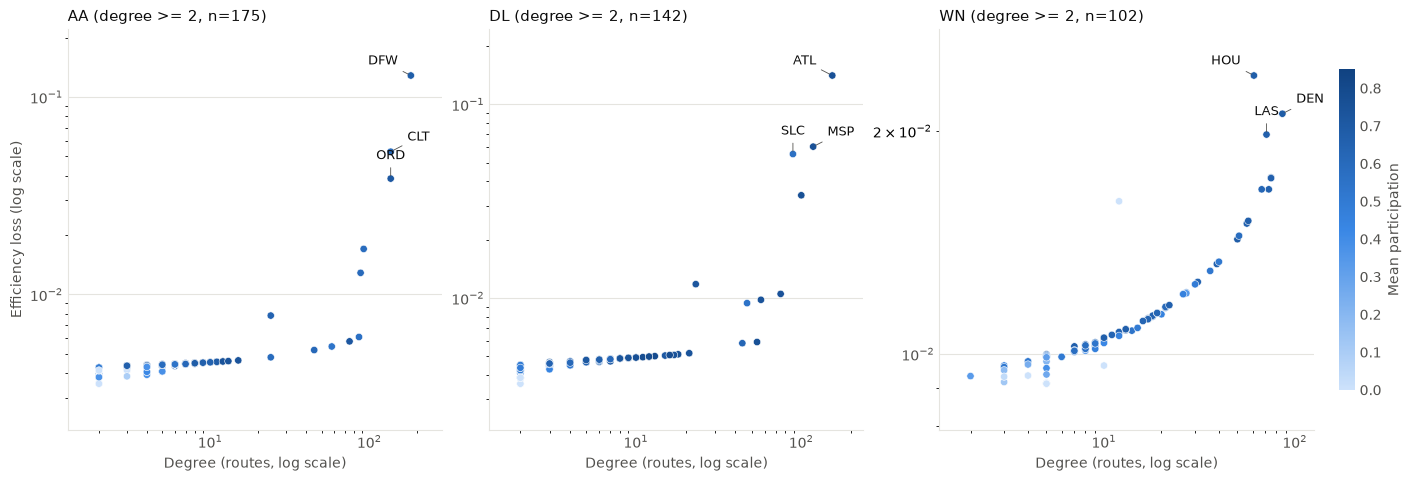

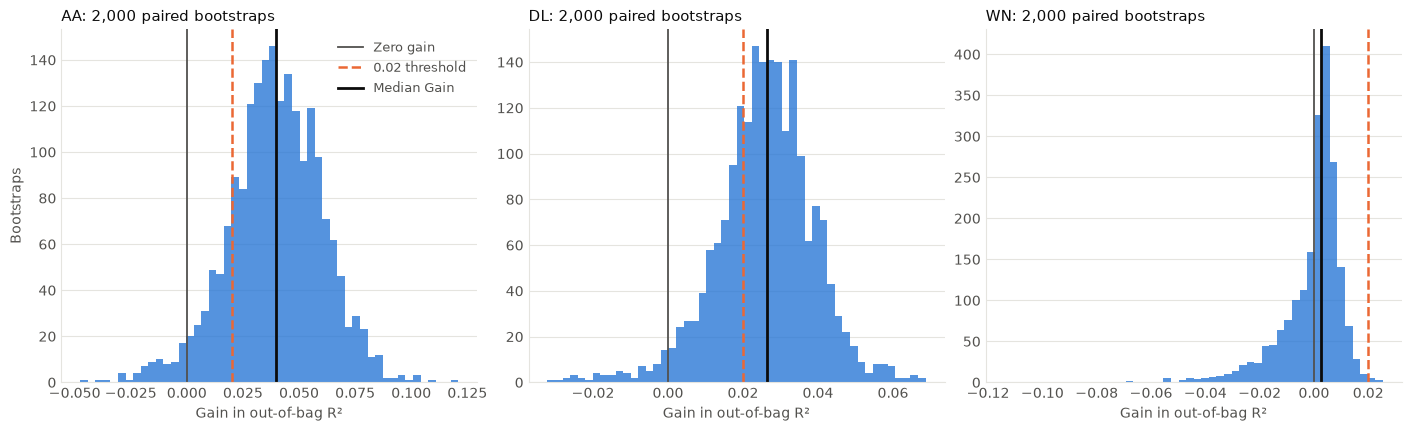

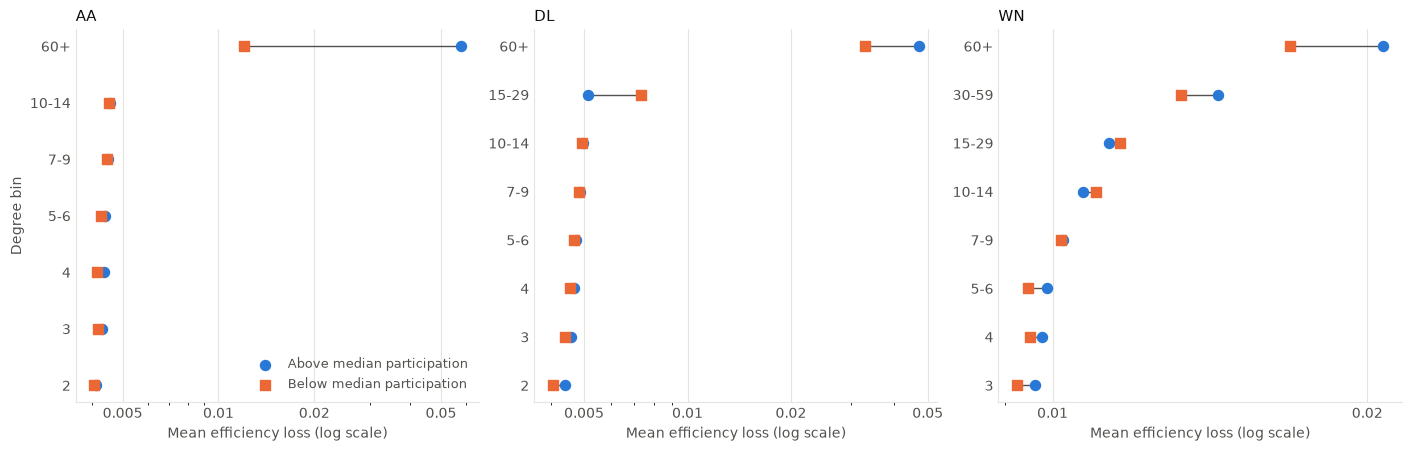

Result
PASS    81
These results describe association or predictive improvement, not causation. Consult the project report: Amani Aghbolagh and Azimi and Manafzadeh and Narehei.docx.


In [10]:
from matplotlib.colors import LinearSegmentedColormap

INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e5e4df"
sequential = LinearSegmentedColormap.from_list("participation", ["#cde2fb", "#3987e5", "#104281"])


def style_axis(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 3, figsize=(14, 4.7), constrained_layout=True)
for ax, airline in zip(axes, AIRLINES):
    data = eligible_df[eligible_df["Airline"] == airline]
    points = ax.scatter(data["Degree"], data["Efficiency loss"], c=data["Participation mean"], cmap=sequential, vmin=0, vmax=0.85, s=28, edgecolor="white", linewidth=0.4)
    ax.set_xscale("log")
    ax.set_yscale("log")
    for offset, (_, row) in zip([(-20, 8), (20, 8), (0, 14)], numerical_top(data, "Efficiency loss", 3).iterrows()):
        ax.annotate(row["Code"], (row["Degree"], row["Efficiency loss"]), xytext=offset, textcoords="offset points", fontsize=9, color=INK, ha="center",
                    arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.6})
    ax.set_xlabel("Degree (routes, log scale)", color=MUTED)
    ax.set_title(f"{airline} (degree >= 2, n={len(data)})", color=INK, fontsize=11, loc="left")
    ax.margins(x=0.1, y=0.15)
    style_axis(ax)
axes[0].set_ylabel("Efficiency loss (log scale)", color=MUTED)
colorbar = fig.colorbar(points, ax=axes, shrink=0.8, pad=0.012)
colorbar.set_label("Mean participation", color=MUTED)
colorbar.outline.set_visible(False)
colorbar.ax.tick_params(colors=MUTED, length=0)
fig.savefig(FIGURES / "07_loss_vs_degree_participation.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)
for ax, airline in zip(axes, AIRLINES):
    gains = bootstrap_df[bootstrap_df["Airline"] == airline]["Gain"].dropna()
    performance = performance_df[performance_df["Airline"] == airline].iloc[0]
    ax.hist(gains, bins=50, color="#2a78d6", alpha=0.8)
    ax.axvline(0, color=MUTED, linewidth=1.3, label="Zero gain")
    ax.axvline(GAIN_THRESHOLD, color="#eb6834", linewidth=1.8, linestyle="--", label="0.02 threshold")
    ax.axvline(performance["Median Gain"], color=INK, linewidth=2, label="Median Gain")
    ax.set_xlabel("Gain in out-of-bag R²", color=MUTED)
    ax.set_title(f"{airline}: 2,000 paired bootstraps", color=INK, fontsize=11, loc="left")
    style_axis(ax)
axes[0].set_ylabel("Bootstraps", color=MUTED)
axes[0].legend(frameon=False, labelcolor=MUTED, fontsize=9)
fig.savefig(FIGURES / "07_h3_gain_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
for ax, airline in zip(axes, AIRLINES):
    data = bins_df[(bins_df["Airline"] == airline) & bins_df["Comparable"]].reset_index(drop=True)
    y = np.arange(len(data))
    ax.scatter(data["Mean loss above median"], y, s=52, color="#2a78d6", zorder=3, label="Above median participation")
    ax.scatter(data["Mean loss below median"], y, s=52, color="#eb6834", marker="s", zorder=3, label="Below median participation")
    ax.hlines(y, data["Mean loss below median"], data["Mean loss above median"], color=MUTED, linewidth=1)
    ax.set_yticks(y, data["Degree bin"].astype(str))
    ax.set_xscale("log")
    limits = ax.get_xlim()
    ax.set_xticks([tick for tick in (0.005, 0.01, 0.02, 0.05) if limits[0] <= tick <= limits[1]], labels=[f"{tick:g}" for tick in (0.005, 0.01, 0.02, 0.05) if limits[0] <= tick <= limits[1]])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlim(limits)
    ax.set_xlabel("Mean efficiency loss (log scale)", color=MUTED)
    ax.set_title(airline, color=INK, fontsize=11, loc="left")
    style_axis(ax)
    ax.yaxis.grid(False)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
axes[0].set_ylabel("Degree bin", color=MUTED)
axes[0].legend(frameon=False, labelcolor=MUTED, fontsize=9)
fig.savefig(FIGURES / "07_degree_matched_loss.png", dpi=300, bbox_inches="tight")
plt.show()

validation_df = pd.DataFrame(validation)
validation_df.to_csv(TABLES / "07_validation_checks.csv", index=False)
pd.DataFrame([{"Stage": key, "Seconds": value} for key, value in timings.items()]).to_csv(TABLES / "07_runtime.csv", index=False)
pd.DataFrame([{"Python": __import__("platform").python_version(), "NetworkX": nx.__version__, "NumPy": np.__version__, "pandas": pd.__version__, "SciPy": scipy.__version__,
               "Master seed": MASTER_SEED, "Bootstraps": BOOTSTRAPS, "Gain threshold (project-specific)": GAIN_THRESHOLD, "Numerical tie decimal places": RANK_DECIMALS}]).to_csv(TABLES / "07_run_metadata.csv", index=False)
print(validation_df["Result"].value_counts().to_string())
print("These results describe association or predictive improvement, not causation. Consult the revised paper: 03_Revision_and_Audit/Amani_Azimi_Manafzadeh_Narehei_Revised_Paper.pdf.")

## Section 7.8 — Nonlinear degree-baseline robustness (formerly Experiment 10)

**Exploratory: the official H3 verdict above is unchanged.**

We retain the exact loss decomposition, survivor-damage sparsity diagnostics, and paired nested cross-validation contrasting linear log-degree, nonlinear spline log-degree, and their participation-augmented counterparts. Repeated splits are sensitivity analyses rather than independent trials. This section intentionally omits the duplicate descriptive partial correlations and degree-bin illustrations from the original 10, which can be found in the archive. All new outputs remain in `Results/Supplementary`.

In [12]:
from supplementary_helpers import *
from sklearn.model_selection import StratifiedKFold,KFold,GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import SplineTransformer,StandardScaler
from sklearn.linear_model import Ridge
begin('10')
airports=read('07_single_airport_outcomes.csv')
eligible=airports[airports['Eligible (degree >= 2)']].copy()
OUTCOMES=['Efficiency loss','Surviving-airport damage']
for a,g in airports.groupby('Airline'):
    n=len(g)
    identity=g['Direct contribution']/(n*(n-1))+(n-2)/n*g['Surviving-airport damage']
    check(f'{a}: loss decomposition',np.allclose(identity,g['Efficiency loss'],atol=1e-12,rtol=0))
    check(f'{a}: survivor definition',np.allclose(g['Survivor efficiency before']-g['Survivor efficiency after'],g['Surviving-airport damage'],atol=1e-12,rtol=0))
    check(f'{a}: eligible population',len(eligible[eligible.Airline==a])==sum(g.Degree>=2))
save(eligible,'10_eligible_airports.csv')
sparsity=[]
for a,g in eligible.groupby('Airline'):
    damage=g['Surviving-airport damage'];positive=damage>1e-12
    sparsity.append({'Airline':a,'Eligible airports':len(g),'Positive survivor damage':int(positive.sum()),'Zero-damage share':float((~positive).mean()),'Median positive damage':damage[positive].median(),'Maximum damage':damage.max(),'Distinct degrees':g.Degree.nunique()})
save(pd.DataFrame(sparsity),'10_sparsity.csv');display(pd.DataFrame(sparsity))

,Airline,Eligible airports,Positive survivor damage,Zero-damage share,Median positive damage,Maximum damage,Distinct degrees
0,AA,175,10,0.942857,0.004983,0.121766,22
1,DL,142,9,0.936620,0.006628,0.133988,27
2,WN,102,12,0.882353,0.000714,0.008646,38


### Nonlinear held-out predictive value, with paired test splits

Training-only transformations and inner tuning preserve the original exploratory analysis; its scores are **not** substituted into the official H3 rule.

In [13]:
def estimator(flexible,participation):
    degree_steps=[('spline',SplineTransformer(n_knots=4,degree=2,include_bias=False)),('scale',StandardScaler())] if flexible else [('scale',StandardScaler())]
    transforms=[('degree',Pipeline(degree_steps),[0])]
    if participation:transforms.append(('participation',StandardScaler(),[1]))
    return Pipeline([('features',ColumnTransformer(transforms)),('ridge',Ridge())])

perf_rows,pred_rows,split_rows,tuning_rows=[],[],[],[]
for ai,a in enumerate(AIRLINES):
    g=eligible[eligible.Airline==a].sort_values('AirportID').reset_index(drop=True)
    X=np.column_stack([np.log1p(g.Degree),g['Participation mean']]);strata=(g['Surviving-airport damage']>1e-12).astype(int)
    check(f'{a}: sparse-event stratification possible',strata.value_counts().min()>=5)
    for repeat in range(5):
        split=list(StratifiedKFold(5,shuffle=True,random_state=SEED+100*ai+repeat).split(X,strata))
        test_counts=np.zeros(len(g),int)
        for fold,(train,test) in enumerate(split):
            check(f'{a}/{repeat}/{fold}: no train-test overlap',len(np.intersect1d(train,test))==0)
            test_counts[test]+=1
            for i in test:split_rows.append({'Airline':a,'Repeat':repeat,'Fold':fold,'AirportID':int(g.loc[i,'AirportID']),'Positive survivor damage':int(strata.iloc[i])})
        check(f'{a}/{repeat}: every airport tested once',np.all(test_counts==1))
        for outcome in OUTCOMES:
            y=g[outcome].to_numpy(float)
            for flexible in [False,True]:
                for participation in [False,True]:
                    label=('Spline degree' if flexible else 'Linear log-degree')+(' + participation' if participation else '')
                    pred=np.empty(len(g));baseline=np.empty(len(g))
                    for fold,(train,test) in enumerate(split):
                        fit=GridSearchCV(estimator(flexible,participation),{'ridge__alpha':[.1,1.,10.,100.]},cv=KFold(3,shuffle=True,random_state=SEED+fold),scoring='neg_mean_squared_error')
                        fit.fit(X[train],y[train]);pred[test]=fit.predict(X[test]);baseline[test]=y[train].mean()
                        tuning_rows.append({'Airline':a,'Outcome':outcome,'Model':label,'Repeat':repeat,'Fold':fold,'Alpha':fit.best_params_['ridge__alpha']})
                    check(f'{a}/{repeat}/{outcome}/{label}: finite held-out predictions',np.isfinite(pred).all())
                    sse=np.sum((y-pred)**2);base_sse=np.sum((y-baseline)**2)
                    perf_rows.append({'Airline':a,'Outcome':outcome,'Model':label,'Repeat':repeat,'Airports':len(g),'OOF RMSE':np.sqrt(sse/len(g)),'OOF R2':1-sse/np.sum((y-y.mean())**2),'Training-mean skill':1-sse/base_sse,'Negative prediction share':np.mean(pred<0)})
                    pred_rows.extend({'Airline':a,'Outcome':outcome,'Model':label,'Repeat':repeat,'AirportID':int(g.loc[i,'AirportID']),'Actual':y[i],'OOF prediction':pred[i],'Training mean':baseline[i]} for i in range(len(g)))
        print(a,'repeat',repeat+1,'complete',flush=True)
performance=pd.DataFrame(perf_rows);predictions=pd.DataFrame(pred_rows)
save(performance,'10_cv_performance.csv');save(predictions,'10_oof_predictions.csv');save(pd.DataFrame(split_rows),'10_cv_splits.csv');save(pd.DataFrame(tuning_rows),'10_tuning.csv')
gain_rows=[]
for (a,outcome,repeat),g in performance.groupby(['Airline','Outcome','Repeat']):
    g=g.set_index('Model')
    for model in ['Linear log-degree','Spline degree']:
        base=g.loc[model];aug=g.loc[model+' + participation']
        gain_rows.append({'Airline':a,'Outcome':outcome,'Degree baseline':model,'Repeat':repeat,'R2 gain from participation':aug['OOF R2']-base['OOF R2'],'RMSE improvement from participation':base['OOF RMSE']-aug['OOF RMSE']})
gains=pd.DataFrame(gain_rows);save(gains,'10_participation_prediction_gain.csv')
summary=gains.groupby(['Airline','Outcome','Degree baseline']).agg(Median_R2_gain=('R2 gain from participation','median'),Min_R2_gain=('R2 gain from participation','min'),Max_R2_gain=('R2 gain from participation','max'),Positive_repeats=('R2 gain from participation',lambda x:int((x>0).sum()))).reset_index()
save(summary,'10_prediction_gain_summary.csv');display(summary)

AA repeat 1 complete
AA repeat 2 complete
AA repeat 3 complete
AA repeat 4 complete
AA repeat 5 complete
DL repeat 1 complete
DL repeat 2 complete
DL repeat 3 complete
DL repeat 4 complete
DL repeat 5 complete
WN repeat 1 complete
WN repeat 2 complete
WN repeat 3 complete
WN repeat 4 complete
WN repeat 5 complete


,Airline,Outcome,Degree baseline,Median_R2_gain,Min_R2_gain,Max_R2_gain,Positive_repeats
0,AA,Efficiency loss,Linear log-degree,0.019818,0.006196,0.026858,5
1,AA,Efficiency loss,Spline degree,-0.000114,-0.000208,-0.000080,0
2,AA,Surviving-airport damage,Linear log-degree,0.025328,0.007656,0.066321,5
3,AA,Surviving-airport damage,Spline degree,-0.000144,-0.000310,-0.000084,0
4,DL,Efficiency loss,Linear log-degree,0.018071,0.001622,0.042444,5
5,DL,Efficiency loss,Spline degree,0.000108,-0.001835,0.000528,3
6,DL,Surviving-airport damage,Linear log-degree,0.021071,-0.041587,0.105824,4
7,DL,Surviving-airport damage,Spline degree,0.000300,-0.001980,0.001091,4
8,WN,Efficiency loss,Linear log-degree,-0.000660,-0.005946,0.000814,1
9,WN,Efficiency loss,Spline degree,-0.018559,-0.021064,-0.015831,0


In [14]:
# Limited matching-coverage diagnostic: no additional descriptive matching models.
peer_rows = []
for airline, group in eligible.groupby('Airline'):
    counts_by_degree = group.groupby('Degree').size()
    for _, airport in group.iterrows():
        peer_rows.append({
            'Airline': airline,
            'AirportID': airport['AirportID'],
            'Code': airport['Code'],
            'Degree': airport['Degree'],
            'Exact-degree peers': int(counts_by_degree.loc[airport['Degree']] - 1),
            'Positive survivor damage': bool(airport['Surviving-airport damage'] > 1e-12),
            'Survivor damage': airport['Surviving-airport damage'],
        })
peer_coverage = pd.DataFrame(peer_rows)
save(peer_coverage, '10_exact_degree_coverage.csv')
display(peer_coverage.groupby('Airline').apply(
    lambda g: pd.Series({
        'High-damage airports': int(g['Positive survivor damage'].sum()),
        'High-damage airports with degree peer': int((g['Positive survivor damage'] & g['Exact-degree peers'].gt(0)).sum()),
    }), include_groups=False,
))

,High-damage airports,High-damage airports with degree peer
Airline,,
AA,10,3
DL,9,0
WN,12,3


In [15]:
# Focused figure: incremental out-of-fold R² from adding participation.
fig, axes = plt.subplots(2, 3, figsize=(11, 7), sharex=True)
for outcome_i, outcome in enumerate(OUTCOMES):
    for airline_i, airline in enumerate(AIRLINES):
        ax = axes[outcome_i, airline_i]
        for x, baseline in enumerate(['Linear log-degree', 'Spline degree']):
            values = gains[(gains.Airline == airline) &
                           (gains.Outcome == outcome) &
                           (gains['Degree baseline'] == baseline)]['R2 gain from participation'].to_numpy()
            ax.scatter(x + np.linspace(-.08, .08, len(values)), values, s=26)
            ax.plot([x - .15, x + .15], [np.median(values)] * 2, color='black')
        ax.axhline(0, color='grey', lw=1)
        ax.set_xticks([0, 1], ['Linear log-degree', 'Spline degree'], rotation=15)
        ax.set_title(f'{airline} — {outcome}')
        ax.grid(alpha=.2)
        if airline_i == 0:
            ax.set_ylabel('Held-out R² gain from participation')
fig.suptitle('Five paired split repeats; dots are sensitivity checks, not independent estimates')
fig.tight_layout()
figure('10_prediction_gain')
finish()

10: 223 checks passed


## Section 7.9: Exploratory decomposition and neighbour-degree check for H3

**Exploratory. Nothing in this section changes the H3 rule, its inputs or the verdicts in Section 7.6.** These cells were added during the paper revision (November 2026). They use the saved single-airport results of Section 7.1 and the saved 2,000 bootstrap samples of Section 7.5, and they draw no new random numbers.

**Cell A** describes the two parts of the single-airport loss (the identity of Section 7.0):

ΔE_i = H_i / (N(N−1)) + ((N−2)/N) · D_i

- H_i is the `Direct contribution` column: 1/d summed over the pairs to and from airport i.
- D_i is the surviving-airport damage.
- In the reciprocal, strongly connected networks used here, H_i = 2·h_i, where h_i = Σ_j 1/d_ij is the harmonic centrality of i.
- The own term can also be written as (N − 1 + k_i − Σ_{r≥3} (1 − 2/r)·n_{r,i}) / (N(N−1)), where n_{r,i} is the number of airports exactly r legs from i. Cell A checks this for every airport.

**Cell B** repeats the partial rank correlation of H3 condition (i) with the mean degree of an airport's neighbours as a second control. It uses the same airports, the same 12-decimal rank convention, the same in-bag rank function and the same bootstrap samples as Section 7.5. As a check, it first reproduces the official degree-only result exactly.

**How to run.** Like Section 7.8, this section is self-contained. It reads the saved outputs of Sections 7.0–7.6 from `Results/Tables` and `Data/Processed` instead of variables in memory, so it also works after a kernel restart (for example after a `%pip install` cell). Run Sections 7.0–7.6 at least once first, then Cell A, then Cell B.

- The project folder is found in the same order as Section 7.0: the `NETWORK_ANALYSIS_LOCAL_ROOT` environment variable, then the current folder if it contains `Data`, then the project's Google Drive folder in Colab.
- Outputs go to `Results/Supplementary`, or to `NETWORK_ANALYSIS_SUPPLEMENT_ROOT` if it is set, as in `supplementary_helpers`.
- Names in this section start with `SECTION_` or `section_`, so they do not depend on, or overwrite, the variables of earlier sections (Section 7.8 redefines `TABLES`, `FIGURES` and `check`).

In [16]:
# Cell A (exploratory, descriptive): the two parts of the single-airport loss.
# Self-contained: reads the saved outputs of Sections 7.0-7.6, so it also runs after a kernel restart.
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path


def section_project_root():
    """Project folder, found in the same order as Section 7.0."""
    local_root = os.environ.get("NETWORK_ANALYSIS_LOCAL_ROOT")
    if local_root:
        return Path(local_root).expanduser().resolve()
    if (Path.cwd() / "Data").is_dir():
        return Path.cwd()
    from google.colab import drive
    drive.mount("/content/drive")
    return Path("/content/drive/MyDrive/Network Analysis ")   # trailing space, as in Section 7.0


SECTION_ROOT = section_project_root()
SECTION_PROCESSED = SECTION_ROOT / "Data" / "Processed"
SECTION_H3_STORE = SECTION_PROCESSED / "H3"
SECTION_TABLES_IN = SECTION_ROOT / "Results" / "Tables"
SECTION_SUPPLEMENT = Path(os.environ.get("NETWORK_ANALYSIS_SUPPLEMENT_ROOT", str(SECTION_ROOT / "Results" / "Supplementary"))).resolve()
SECTION_TABLES_OUT = SECTION_SUPPLEMENT / "Tables"
SECTION_VALIDATION = SECTION_SUPPLEMENT / "Validation"
SECTION_TABLES_OUT.mkdir(parents=True, exist_ok=True)
SECTION_VALIDATION.mkdir(parents=True, exist_ok=True)

# Settings of Section 7.0; checked against the saved run metadata below.
SECTION_AIRLINES = ["AA", "DL", "WN"]
SECTION_MASTER_SEED = 20250401
SECTION_STAGE_H3_BOOTSTRAP = 8
SECTION_BOOTSTRAPS = 2000
SECTION_RANK_DECIMALS = 12
SECTION_TOLERANCE = 1e-12
section_checks = []


class SectionCheckError(RuntimeError):
    pass


def section_check(name, condition, detail=""):
    """Record a Section 7.9 check; stop immediately if it fails."""
    passed = bool(condition)
    section_checks.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": str(detail)})
    if not passed:
        pd.DataFrame(section_checks).to_csv(SECTION_VALIDATION / "07_h3_section_7_9_checks.csv", index=False)
        raise SectionCheckError(f"FAILED: {name}. {detail}")


# The same conventions as Sections 7.0, 7.3 and 7.5, under section-specific names.
def section_ranking_values(values):
    return np.round(np.asarray(values, dtype=float), SECTION_RANK_DECIMALS)


def section_numerical_top(frame, column, k):
    ids = frame["AirportID"].to_numpy()
    return frame.iloc[np.lexsort((ids, -section_ranking_values(frame[column])))[:k]]


def section_rank_function(train_values, values):
    ordered = np.sort(section_ranking_values(train_values))
    values = section_ranking_values(values)
    return (np.searchsorted(ordered, values, side="left") + np.searchsorted(ordered, values, side="right")) / (2 * len(train_values))


def section_design(*columns):
    return np.column_stack([np.ones(len(columns[0])), *columns])


def section_interval(values):
    clean = values[~np.isnan(values)]
    return float(np.percentile(clean, 2.5)), float(np.percentile(clean, 97.5)), float(np.median(clean))


# Saved inputs from Sections 7.0-7.6.
required = [SECTION_TABLES_IN / name for name in ["07_single_airport_outcomes.csv", "07_surviving_damage_summary.csv", "07_top_efficiency_loss_airports.csv",
                                                  "07_h3_partial_correlation.csv", "07_h3_model_performance.csv", "07_h3_verdicts.csv", "07_run_metadata.csv"]]
required += [SECTION_PROCESSED / f"{airline}_{kind}.csv" for airline in SECTION_AIRLINES for kind in ("nodes", "edges")]
required += [SECTION_H3_STORE / f"{airline}_bootstrap_inbag_indices.npz" for airline in SECTION_AIRLINES]
missing = [str(path) for path in required if not path.is_file()]
section_check("Saved inputs of Sections 7.0-7.6 are present (run them first if not)", not missing, missing)

run_metadata = pd.read_csv(SECTION_TABLES_IN / "07_run_metadata.csv").iloc[0]
section_check("Settings match the saved run metadata",
              int(run_metadata["Master seed"]) == SECTION_MASTER_SEED and int(run_metadata["Bootstraps"]) == SECTION_BOOTSTRAPS
              and int(run_metadata["Numerical tie decimal places"]) == SECTION_RANK_DECIMALS)
section_check("Rank function matches its definition", np.isclose(section_rank_function(np.array([1, 2, 2, 3.0]), np.array([2.0]))[0], 0.5, atol=1e-12))

single_saved = pd.read_csv(SECTION_TABLES_IN / "07_single_airport_outcomes.csv")
section_check("Eligibility column is read as boolean", single_saved["Eligible (degree >= 2)"].dtype == bool)
damage_summary = pd.read_csv(SECTION_TABLES_IN / "07_surviving_damage_summary.csv")
top_loss_saved = pd.read_csv(SECTION_TABLES_IN / "07_top_efficiency_loss_airports.csv")

SECTION_DATA = {}
decomposition_rows, top_loss_rows = [], []
for airline in SECTION_AIRLINES:
    # Network as in Section 7.0: sorted BTS airport IDs and arc end points as positions in that order.
    nodes = pd.read_csv(SECTION_PROCESSED / f"{airline}_nodes.csv")
    edges = pd.read_csv(SECTION_PROCESSED / f"{airline}_edges.csv")
    network_ids = np.sort(nodes["airport_id"].to_numpy(dtype=np.int64))
    source = np.searchsorted(network_ids, edges["source"].to_numpy(dtype=np.int64))
    target = np.searchsorted(network_ids, edges["target"].to_numpy(dtype=np.int64))
    n_airports = len(network_ids)
    airports = single_saved[single_saved["Airline"] == airline].sort_values("AirportID").reset_index(drop=True)
    section_check(f"{airline}: saved single-airport rows match the network", np.array_equal(airports["AirportID"].to_numpy(), network_ids))
    SECTION_DATA[airline] = {"ids": network_ids, "n": n_airports, "source": source, "target": target, "airports": airports}

    loss = airports["Efficiency loss"].to_numpy(float)
    direct = airports["Direct contribution"].to_numpy(float)          # H_i
    damage = airports["Surviving-airport damage"].to_numpy(float)     # D_i
    degree = airports["Degree"].to_numpy(float)
    eligible = airports["Eligible (degree >= 2)"].to_numpy(bool)
    own_term = direct / (n_airports * (n_airports - 1))
    survivor_term = (n_airports - 2) / n_airports * damage
    has_damage = damage > SECTION_TOLERANCE
    section_check(f"{airline}: loss equals own term plus survivor term", np.allclose(loss, own_term + survivor_term, rtol=0, atol=SECTION_TOLERANCE))
    section_check(f"{airline}: zero survivor damage means loss equals the own term",
                  np.allclose(loss[~has_damage], own_term[~has_damage], rtol=0, atol=SECTION_TOLERANCE), int((~has_damage).sum()))

    # Distances on the intact network: one shortest-path calculation per airline, same call as Section 7.1.
    adjacency_matrix = csr_matrix((np.ones(len(source)), (source, target)), shape=(n_airports, n_airports))
    distances = shortest_path(adjacency_matrix, method="D", unweighted=True, directed=True)
    off_diagonal = ~np.eye(n_airports, dtype=bool)
    section_check(f"{airline}: network is strongly connected", np.isfinite(distances[off_diagonal]).all())
    section_check(f"{airline}: distances are symmetric (fully reciprocal routes)", np.array_equal(distances, distances.T))
    inverse = np.zeros_like(distances)
    inverse[off_diagonal] = 1.0 / distances[off_diagonal]
    harmonic = inverse.sum(axis=1)                                      # h_i = sum over j of 1/d_ij
    section_check(f"{airline}: H_i equals twice the harmonic centrality", np.allclose(direct, 2 * harmonic, rtol=0, atol=SECTION_TOLERANCE))
    longest = int(distances[off_diagonal].max())
    shells = {r: (distances == r).sum(axis=1) for r in range(1, longest + 1)}   # n_{r,i}
    section_check(f"{airline}: airports one leg away equal degree", np.array_equal(shells[1], degree.astype(int)))
    shell_form = (n_airports - 1 + degree - sum((1 - 2 / r) * shells[r] for r in shells if r >= 3)) / (n_airports * (n_airports - 1))
    section_check(f"{airline}: shell form of the own term", np.allclose(own_term, shell_form, rtol=0, atol=SECTION_TOLERANCE))

    # Cross-checks with tables already produced in Sections 7.3 and 7.6.
    summary_row = damage_summary[damage_summary["Airline"] == airline].iloc[0]
    section_check(f"{airline}: eligible airports with survivor damage match Section 7.6",
                  int((has_damage & eligible).sum()) == int(summary_row["Eligible airports with damage above 0"]))
    composition = airports.assign(**{"Own term": own_term, "Survivor term": survivor_term})
    top_five = section_numerical_top(composition, "Efficiency loss", 5)
    saved_top_five = top_loss_saved[top_loss_saved["Airline"] == airline].sort_values("Rank")["Code"].head(5).tolist()
    section_check(f"{airline}: top-5 loss airports match Section 7.3", top_five["Code"].tolist() == saved_top_five, saved_top_five)

    loss_rank_input = pd.Series(section_ranking_values(loss[eligible]))
    decomposition_rows.append({
        "Airline": airline, "Airports": n_airports, "Eligible airports (degree >= 2)": int(eligible.sum()),
        "Longest shortest path (legs)": longest,
        "Own-term share of summed loss (all airports)": own_term.sum() / loss.sum(),
        "Airports with survivor damage > 0": int(has_damage.sum()),
        "Eligible airports with survivor damage > 0": int((has_damage & eligible).sum()),
        "Eligible airports with zero survivor damage": int((~has_damage & eligible).sum()),
        "Top-3 share of summed survivor damage": np.sort(damage)[::-1][:3].sum() / damage.sum(),
        "Spearman(loss, harmonic centrality), eligible": loss_rank_input.corr(pd.Series(section_ranking_values(harmonic[eligible])), method="spearman"),
        "Spearman(loss, degree), eligible": loss_rank_input.corr(pd.Series(section_ranking_values(degree[eligible])), method="spearman"),
        "Status": "Exploratory; descriptive only",
    })

    # Composition of the five largest single-airport losses (same tie rule as the other top-k lists).
    for rank, (_, row) in enumerate(top_five.iterrows(), 1):
        top_loss_rows.append({"Airline": airline, "Rank": rank, "Code": row["Code"], "Degree": int(row["Degree"]),
                              "Efficiency loss": row["Efficiency loss"],
                              "Own-term share of loss": row["Own term"] / row["Efficiency loss"],
                              "Survivor-damage share of loss": row["Survivor term"] / row["Efficiency loss"]})

decomposition_df = pd.DataFrame(decomposition_rows)
top_loss_composition_df = pd.DataFrame(top_loss_rows)
decomposition_df.to_csv(SECTION_TABLES_OUT / "07_h3_loss_decomposition_summary.csv", index=False)
top_loss_composition_df.to_csv(SECTION_TABLES_OUT / "07_h3_top_loss_composition.csv", index=False)
SECTION_79_READY = True
eligible_total = int(decomposition_df["Eligible airports (degree >= 2)"].sum())
zero_total = int(decomposition_df["Eligible airports with zero survivor damage"].sum())
print("Project folder:", SECTION_ROOT)
print(f"Eligible airports with zero survivor damage: {zero_total} of {eligible_total} ({zero_total / eligible_total:.1%})")
display(decomposition_df.set_index("Airline").T)
display(top_loss_composition_df.round(4))

Project folder: c:\Users\GigaTech\Desktop\Network_Analysis_Complete_Project_Package\Network_Analysis_Complete_Project_Package\02_Optional_Reproducible_Project
Eligible airports with zero survivor damage: 388 of 419 (92.6%)


Airline,AA,DL,WN
Airports,230,212,104
Eligible airports (degree >= 2),175,142,102
Longest shortest path (legs),4,4,4
Own-term share of summed loss (all airports),0.817878,0.773559,0.978826
Airports with survivor damage > 0,10,9,12
Eligible airports with survivor damage > 0,10,9,12
Eligible airports with zero survivor damage,165,133,90
Top-3 share of summed survivor damage,0.904361,0.838178,0.737272
"Spearman(loss, harmonic centrality), eligible",0.999966,0.999929,0.966586
"Spearman(loss, degree), eligible",0.909251,0.954664,0.971824


,Airline,Rank,Code,Degree,Efficiency loss,Own-term share of loss,Survivor-damage share of loss
0,AA,1,DFW,182,0.1285,0.0607,0.9393
1,AA,2,CLT,136,0.0529,0.1311,0.8689
2,AA,3,ORD,136,0.0386,0.1794,0.8206
3,AA,4,PHX,92,0.0170,0.3584,0.6416
4,AA,5,PHL,88,0.0129,0.4673,0.5327
5,DL,1,ATL,154,0.1409,0.0579,0.9421
6,DL,2,MSP,118,0.0605,0.1216,0.8784
7,DL,3,SLC,89,0.0554,0.1211,0.8789
8,DL,4,DTW,100,0.0339,0.2050,0.7950
9,DL,5,AUS,23,0.0118,0.4431,0.5569


### Neighbour-degree sensitivity of H3 condition (i)

The partial rank correlation of participation with loss is computed three ways, each as a full-sample value and as 2.5th–97.5th percentiles over the 2,000 in-bag samples of Section 7.5:

1. controlling for degree rank only, which must reproduce `07_h3_partial_correlation.csv` exactly;
2. controlling for degree rank and the rank of mean neighbour degree;
3. participation with mean neighbour degree, controlling for degree rank.

Mean neighbour degree is the average degree of an airport's route partners in the full network. The percentiles describe stability across resamples of one network's airports, not population confidence intervals. **No verdict is computed.** Run Cell A first: it sets the paths and loads the saved inputs used here.

In [17]:
# Cell B (exploratory): H3 condition (i) with mean neighbour degree as a second control.
# Same airports, 12-decimal rank convention, in-bag rank function and 2,000 bootstrap samples as Section 7.5.
if not globals().get("SECTION_79_READY"):
    raise RuntimeError("Run Cell A of Section 7.9 first: it sets the project paths and loads the saved inputs used here.")

partial_saved = pd.read_csv(SECTION_TABLES_IN / "07_h3_partial_correlation.csv")
performance_saved = pd.read_csv(SECTION_TABLES_IN / "07_h3_model_performance.csv")
verdicts_saved = pd.read_csv(SECTION_TABLES_IN / "07_h3_verdicts.csv")


def residual_correlation(y_ranks, x_ranks, control_ranks):
    """Correlation of the residuals of y and x after least squares on an intercept and the controls (Section 7.5 method)."""
    z = section_design(*control_ranks)
    residual_y = y_ranks - z @ np.linalg.lstsq(z, y_ranks, rcond=None)[0]
    residual_x = x_ranks - z @ np.linalg.lstsq(z, x_ranks, rcond=None)[0]
    if residual_y.std() == 0 or residual_x.std() == 0:
        return np.nan
    return float(np.corrcoef(residual_y, residual_x)[0, 1])


def full_sample_ranks(values):
    """Average ranks of 12-decimal values, as for the full-sample partial correlation in Section 7.5."""
    return pd.Series(section_ranking_values(values)).rank().to_numpy(float)


neighbour_rows = []
for airline_index, airline in enumerate(SECTION_AIRLINES):
    data = SECTION_DATA[airline]
    n_airports = data["n"]
    h3 = data["airports"][data["airports"]["Eligible (degree >= 2)"]].sort_values("AirportID").reset_index(drop=True)
    loss = h3["Efficiency loss"].to_numpy(float)
    degree = h3["Degree"].to_numpy(float)
    participation = h3["Participation mean"].to_numpy(float)
    h3_ids = h3["AirportID"].to_numpy()

    # The saved bootstrap samples are the official ones: they must match the recorded seed and the H3 airports.
    saved = np.load(SECTION_H3_STORE / f"{airline}_bootstrap_inbag_indices.npz")
    samples = saved["samples"]
    regenerated = np.random.default_rng(np.random.SeedSequence(entropy=SECTION_MASTER_SEED, spawn_key=(SECTION_STAGE_H3_BOOTSTRAP, airline_index, 0))).integers(0, len(h3), size=(SECTION_BOOTSTRAPS, len(h3)))
    section_check(f"{airline}: saved bootstrap samples reproduce from the recorded seed", np.array_equal(samples, regenerated))
    section_check(f"{airline}: saved bootstrap samples belong to the H3 airports", np.array_equal(saved["airport_ids"], h3_ids))
    section_check(f"{airline}: no degenerate bootstraps in Section 7.5",
                  int(performance_saved.loc[performance_saved["Airline"] == airline, "Degenerate bootstraps"].iloc[0]) == 0)

    # Mean neighbour degree in the full network (routes are reciprocal, so neighbours are out-neighbours).
    adjacency_matrix = csr_matrix((np.ones(len(data["source"])), (data["source"], data["target"])), shape=(n_airports, n_airports))
    section_check(f"{airline}: adjacency is symmetric", (adjacency_matrix != adjacency_matrix.T).nnz == 0)
    degree_all = np.asarray(adjacency_matrix.sum(axis=1)).ravel()
    mean_neighbour_degree_all = (adjacency_matrix @ degree_all) / degree_all
    position = np.searchsorted(data["ids"], h3_ids)
    section_check(f"{airline}: H3 airports located in the network", np.array_equal(data["ids"][position], h3_ids))
    section_check(f"{airline}: degrees agree with the saved outcomes", np.array_equal(degree_all[position], degree))
    neighbour_degree = mean_neighbour_degree_all[position]

    # Full sample.
    r_loss, r_degree, r_part, r_neigh = (full_sample_ranks(v) for v in (loss, degree, participation, neighbour_degree))
    full = {"degree": residual_correlation(r_loss, r_part, [r_degree]),
            "extended": residual_correlation(r_loss, r_part, [r_degree, r_neigh]),
            "participation_neighbour": residual_correlation(r_neigh, r_part, [r_degree])}

    # Bootstrap: rank functions learned from the in-bag airports only, as in Section 7.5.
    boot = {key: [] for key in full}
    for in_bag in samples:
        b_loss = section_rank_function(loss[in_bag], loss[in_bag])
        b_degree = section_rank_function(degree[in_bag], degree[in_bag])
        b_part = section_rank_function(participation[in_bag], participation[in_bag])
        b_neigh = section_rank_function(neighbour_degree[in_bag], neighbour_degree[in_bag])
        boot["degree"].append(residual_correlation(b_loss, b_part, [b_degree]))
        boot["extended"].append(residual_correlation(b_loss, b_part, [b_degree, b_neigh]))
        boot["participation_neighbour"].append(residual_correlation(b_neigh, b_part, [b_degree]))
    percentiles = {key: section_interval(np.array(values)) for key, values in boot.items()}   # (2.5%, 97.5%, median)

    # The degree-only version must reproduce the official H3 condition (i) exactly.
    official = partial_saved[partial_saved["Airline"] == airline].iloc[0]
    section_check(f"{airline}: degree-only full-sample partial reproduces Section 7.5",
                  np.isclose(full["degree"], official["Partial rank correlation (full sample)"], rtol=0, atol=SECTION_TOLERANCE))
    section_check(f"{airline}: degree-only bootstrap percentiles reproduce Section 7.5",
                  np.allclose(list(percentiles["degree"]), [official["2.5%"], official["97.5%"], official["Bootstrap median"]], rtol=0, atol=SECTION_TOLERANCE))

    labels = {"degree": "Partial(participation, loss | degree)",
              "extended": "Partial(participation, loss | degree, mean neighbour degree)",
              "participation_neighbour": "Partial(participation, mean neighbour degree | degree)"}
    row = {"Airline": airline, "Eligible airports": len(loss), "Bootstraps": len(samples)}
    for key, label in labels.items():
        low, high, median = percentiles[key]
        row.update({f"{label}: full sample": full[key], f"{label}: bootstrap median": median,
                    f"{label}: 2.5%": low, f"{label}: 97.5%": high})
    row["Status"] = "Exploratory; no verdict"
    neighbour_rows.append(row)

neighbour_df = pd.DataFrame(neighbour_rows)
neighbour_df.to_csv(SECTION_TABLES_OUT / "07_h3_neighbour_degree_sensitivity.csv", index=False)
section_checks_df = pd.DataFrame(section_checks)
section_checks_df.to_csv(SECTION_VALIDATION / "07_h3_section_7_9_checks.csv", index=False)
display(neighbour_df.set_index("Airline").T)
print("Section 7.9 checks:", section_checks_df["Result"].value_counts().to_string())
print("H3 verdicts (unchanged, read from Section 7.6):", dict(zip(verdicts_saved["Airline"], verdicts_saved["H3 verdict"])))

Airline,AA,DL,WN
Eligible airports,175,142,102
Bootstraps,2000,2000,2000
"Partial(participation, loss | degree): full sample",0.494478,0.557115,0.278529
"Partial(participation, loss | degree): bootstrap median",0.4928,0.552141,0.28972
"Partial(participation, loss | degree): 2.5%",0.373455,0.412913,-0.073147
"Partial(participation, loss | degree): 97.5%",0.598636,0.678058,0.547824
"Partial(participation, loss | degree, mean neighbour degree): full sample",0.302462,0.42568,0.05638
"Partial(participation, loss | degree, mean neighbour degree): bootstrap median",0.303074,0.42205,0.073542
"Partial(participation, loss | degree, mean neighbour degree): 2.5%",0.164264,0.255075,-0.143342
"Partial(participation, loss | degree, mean neighbour degree): 97.5%",0.431575,0.583341,0.326778


Section 7.9 checks: Result
PASS    58
H3 verdicts (unchanged, read from Section 7.6): {'AA': 'Partly supported', 'DL': 'Partly supported', 'WN': 'Partly supported'}
